In [1]:
import numpy as np
import pandas as pd

In [2]:
data=pd.read_csv('datasets\Salary_Data.csv')

In [3]:
df=pd.DataFrame(data)
df.dtypes

YearsExperience    float64
Salary             float64
dtype: object

In [4]:
x=df.iloc[:,0]
y=df.iloc[:,1]
x

0      1.1
1      1.3
2      1.5
3      2.0
4      2.2
5      2.9
6      3.0
7      3.2
8      3.2
9      3.7
10     3.9
11     4.0
12     4.0
13     4.1
14     4.5
15     4.9
16     5.1
17     5.3
18     5.9
19     6.0
20     6.8
21     7.1
22     7.9
23     8.2
24     8.7
25     9.0
26     9.5
27     9.6
28    10.3
29    10.5
Name: YearsExperience, dtype: float64

In [5]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'salary')

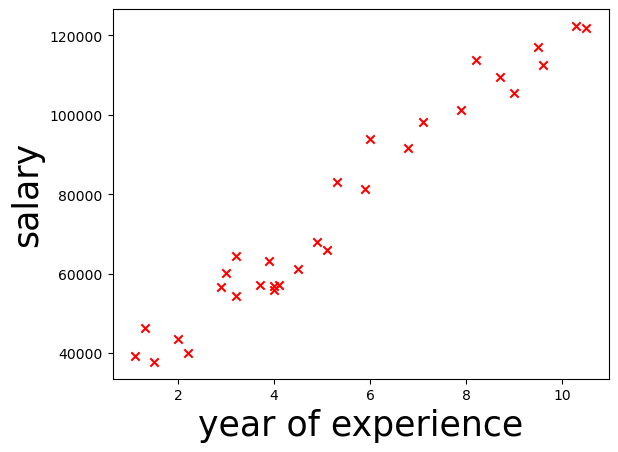

In [6]:
fig,ax=plt.subplots()
ax.scatter(x,y,marker='x',color='red')
ax.set_xlabel("year of experience",fontsize=25)
ax.set_ylabel("salary",fontsize=25)


In [7]:
x=np.expand_dims(x,axis=1,)
y=np.expand_dims(y,axis=1)

In [8]:
from sklearn.model_selection import train_test_split
x_train,x_,y_train,y_=train_test_split(x,y,test_size=0.40,random_state=1)
x_cv,x_test,y_cv,y_test=train_test_split(x_,y_,test_size=0.50,random_state=1)

In [9]:
x_train.shape
x_cv.shape
x_test.shape
x.shape
y.shape

(30, 1)

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score


In [11]:
model=LinearRegression()
model.fit(x_train,y_train)


LinearRegression()

In [12]:
yhat=model.predict(x_train)
mse=(mean_squared_error(yhat,y_train)/2)
print(mse)

11198007.004136525


In [14]:
yhat=model.predict(x_cv)
mse_test=(mean_squared_error(yhat,y_cv)/2)
print(mse_test)

16622305.1821267


In [15]:
from sklearn.preprocessing import PolynomialFeatures,StandardScaler

In [16]:
# Initialize lists to save the errors, models, and feature transforms
train_mses = []
cv_mses = []
models = []
polys = []
scalers = []

# Loop over 10 times. Each adding one more degree of polynomial higher than the last.
for degree in range(1,11):

    # Add polynomial features to the training set
    poly = PolynomialFeatures(degree, include_bias=False)
    X_train_mapped = poly.fit_transform(x_train)
    polys.append(poly)

    # Scale the training set
    scaler_poly = StandardScaler()
    X_train_mapped_scaled = scaler_poly.fit_transform(X_train_mapped)
    scalers.append(scaler_poly)

    # Create and train the model
    model = LinearRegression()
    model.fit(X_train_mapped_scaled, y_train )
    models.append(model)

    # Compute the training MSE
    yhat = model.predict(X_train_mapped_scaled)
    train_mse = mean_squared_error(y_train, yhat) / 2
    train_mses.append(train_mse)

    # Add polynomial features and scale the cross validation set
    X_cv_mapped = poly.transform(x_cv)
    X_cv_mapped_scaled = scaler_poly.transform(X_cv_mapped)

    # Compute the cross validation MSE
    yhat = model.predict(X_cv_mapped_scaled)
    cv_mse = mean_squared_error(y_cv, yhat) / 2
    cv_mses.append(cv_mse)



In [17]:
print(cv_mses)

[16622305.182126628, 29464182.872845814, 34627372.32701151, 38588686.73014754, 37875825.87276645, 35051195.62950964, 36296639.52327475, 35994223.95466878, 34044386.528971456, 149566218.94598973]


In [19]:
degree=np.argmin(cv_mses)+1
print(degree)
cv_mses

1


[16622305.182126628,
 29464182.872845814,
 34627372.32701151,
 38588686.73014754,
 37875825.87276645,
 35051195.62950964,
 36296639.52327475,
 35994223.95466878,
 34044386.528971456,
 149566218.94598973]

In [20]:
X_test_mapped=polys[degree-1].transform(x_test)
X_test_scaled=scalers[degree-1].transform(x_test)
yhat = models[degree-1].predict(X_test_scaled)
test_mse = mean_squared_error(y_test, yhat) / 2


print(f"Training MSE: {train_mses[degree-1]:.2f}")
print(f"Cross Validation MSE: {cv_mses[degree-1]:.2f}")
print(f"Test MSE: {test_mse:.2f}")



Training MSE: 11198007.00
Cross Validation MSE: 16622305.18
Test MSE: 44113426.24
